In [1]:
from pathlib import Path
import re
import json 
import sys
import os

import matplotlib
import matplotlib.pyplot as plt
# %matplotlib notebook
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns  
import pickle as pkl
from tqdm import tqdm
from tensorboard.backend.event_processing import event_accumulator
from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import as_completed

module_path = os.path.abspath(os.path.join('../'))
if module_path not in sys.path:
    sys.path.append(module_path)


In [ ]:
## Load demos

In [2]:
demos_down = pkl.load(open('../demos/demo_hf_CMoveP-v0_10_down.pkl','rb'))
demos_up = pkl.load(open('../demos/demo_hf_CMoveP-v0_10_up.pkl','rb'))
demos_mid = pkl.load(open('../demos/demo_hf_CMoveP-v0_10_mid.pkl','rb'))

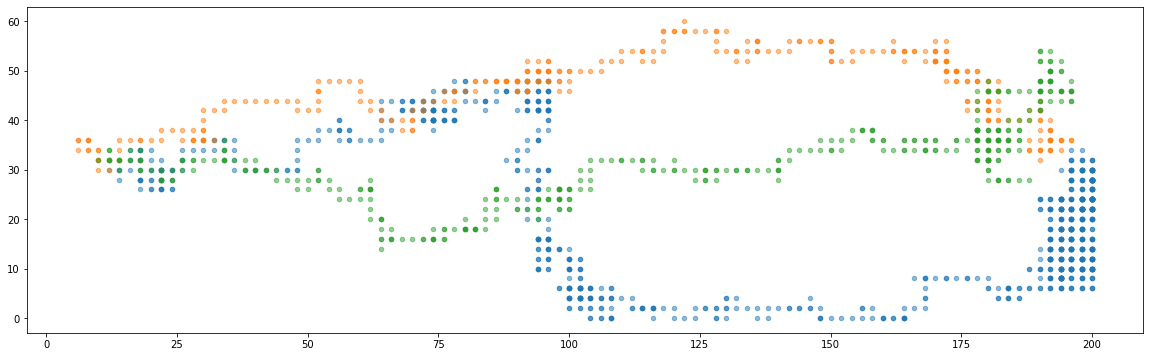

In [10]:
plt.figure(figsize=(20,6))
plt.scatter(demos_down['obs'][:,0], demos_down['obs'][:,1], alpha=0.5, s=20)
plt.scatter(demos_up['obs'][:,0], demos_up['obs'][:,1], alpha=0.5, s=20)
plt.scatter(demos_mid['obs'][:,0], demos_mid['obs'][:,1], alpha=0.5, s=20)

In [74]:
def plot_reward(shape=(200,60), tgt_pos=(190,30), plot_value=False, env=None):
    # generate grid w/ two different targets:
    x = np.arange(0,shape[0])
    y = np.arange(0,shape[1])

    grid = np.array(np.meshgrid(y,x))
    point_list = np.reshape(grid, [2,-1]).T
    #point_list = grid

    tgt_pos = np.array(tgt_pos)
    grid_pos1 = np.concatenate([point_list, np.tile(tgt_pos, (point_list.shape[0],1))],1)

    def dist_f(grid_pos):
        return -(np.sqrt((grid_pos[:,0] - grid_pos[:,3])**2 + (grid_pos[:,1]-grid_pos[:,2])**2))

    r_gt_1 = dist_f(grid_pos1)
    r_gt_1 = r_gt_1.reshape(np.array(shape))

    title = 'reward'

    fig = plt.figure(figsize=(20,5))
    ax1 = plt.subplot(121)
    plt.pcolormesh(x,y,r_gt_1.T)
    plt.colorbar()
    plt.scatter(tgt_pos[0], tgt_pos[1], c='r')
    plt.title(title + '_irl')
    ax2 = plt.subplot(122)
    plt.pcolor(x,y,r_gt_1.T)
    plt.colorbar()
    plt.scatter(tgt_pos[0], tgt_pos[1], c='r')
    plt.title(title + '_gt')
    
    plt.tight_layout()

    fig.canvas.draw()
    data = np.frombuffer(fig.canvas.tostring_rgb(), dtype=np.uint8)

    image_from_plot = (data.reshape(fig.canvas.get_width_height()[::-1] + (3,)) / 255.0)
    img = np.swapaxes(image_from_plot, 0, 2)
    img = np.swapaxes(img, 1, 2)

    return img

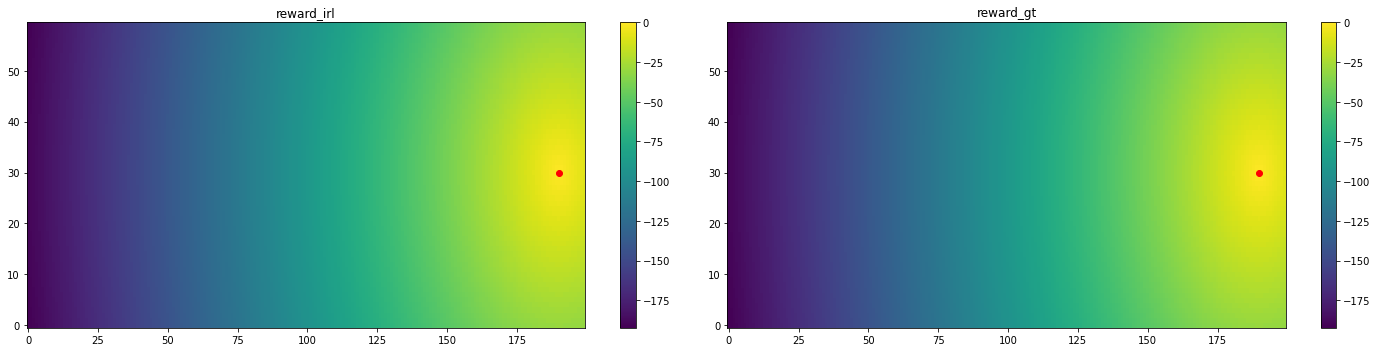

In [75]:
img = plot_reward()